Saving image.jp2 to image (1).jp2


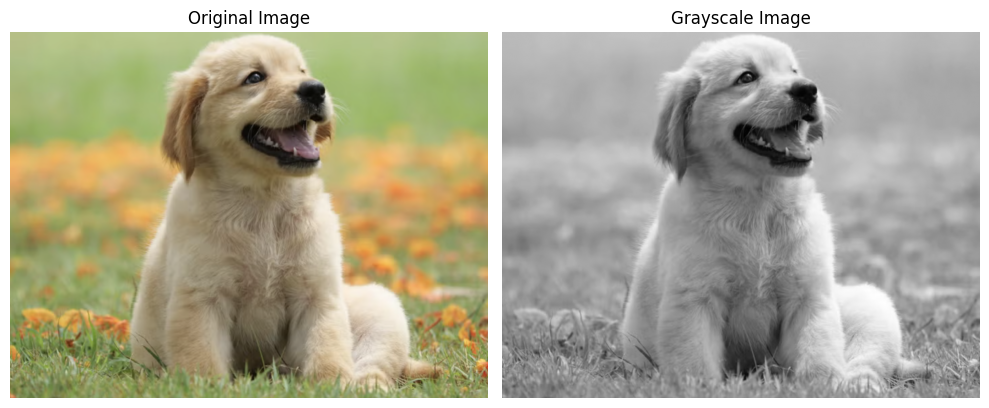

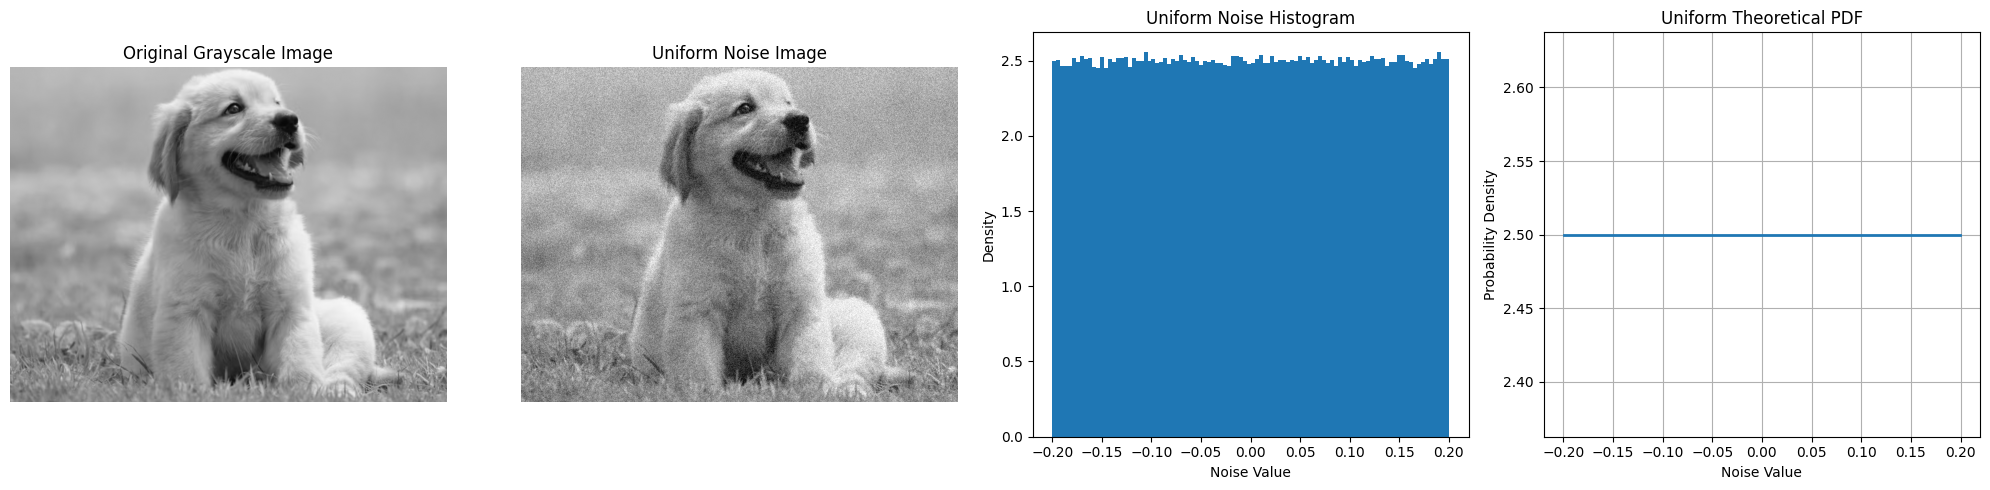

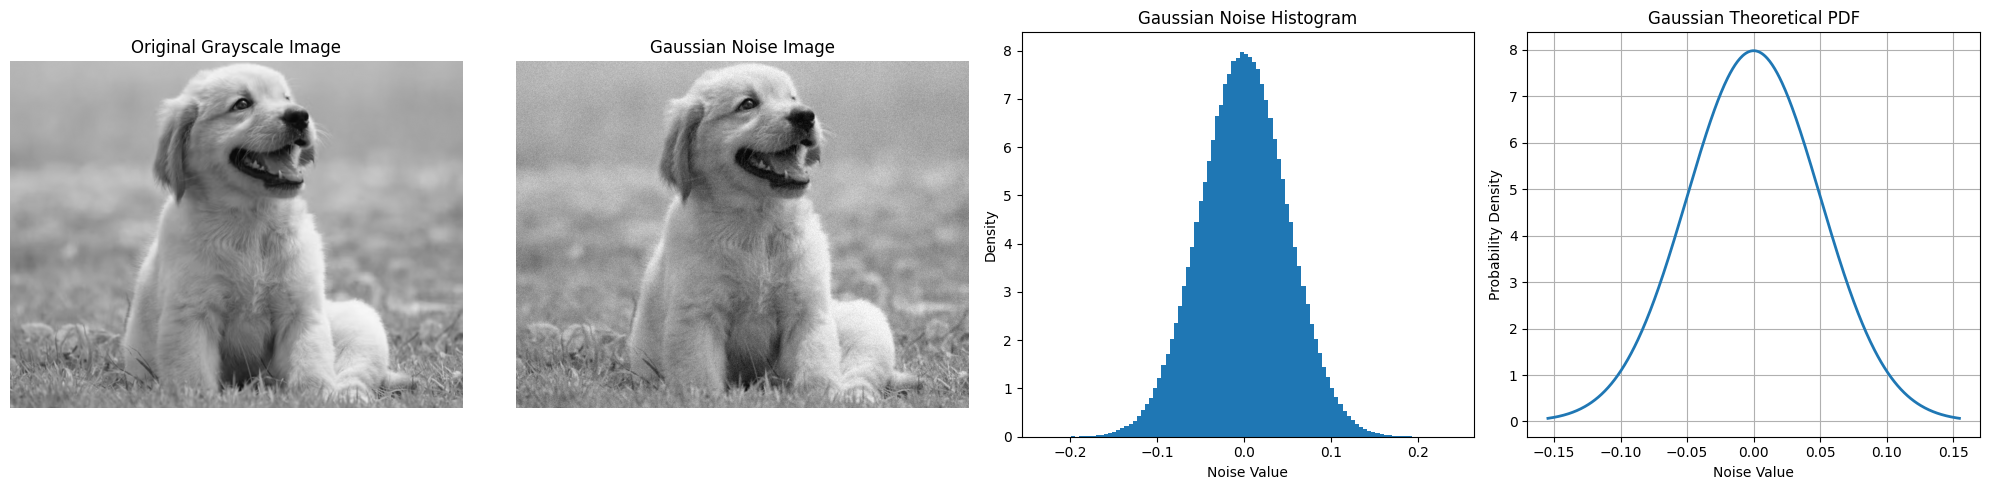

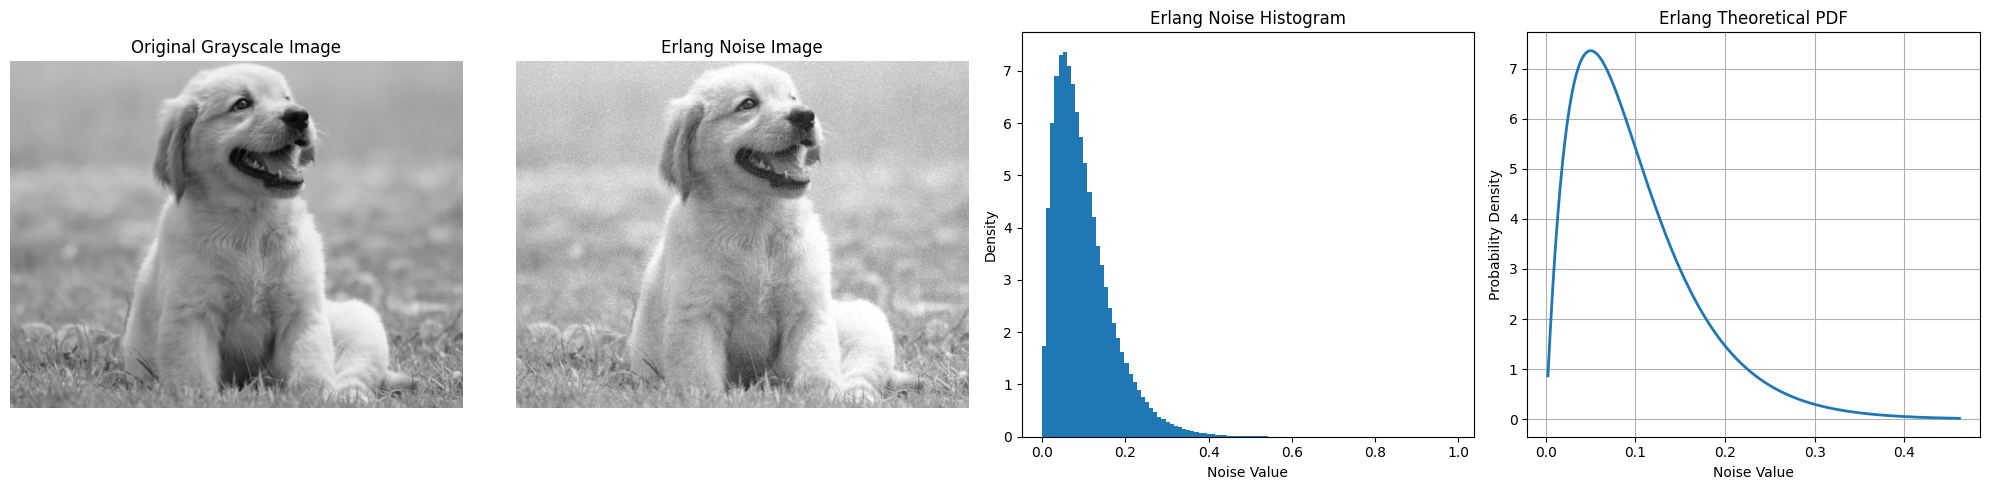

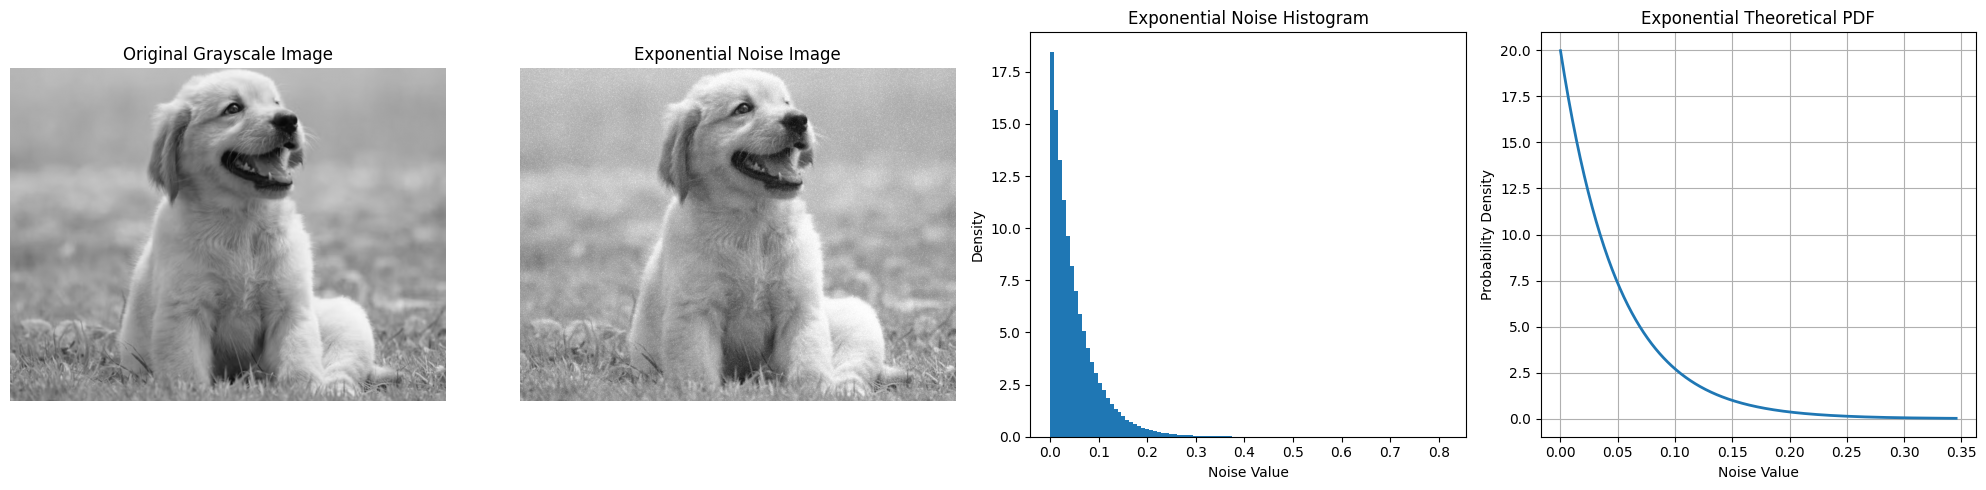

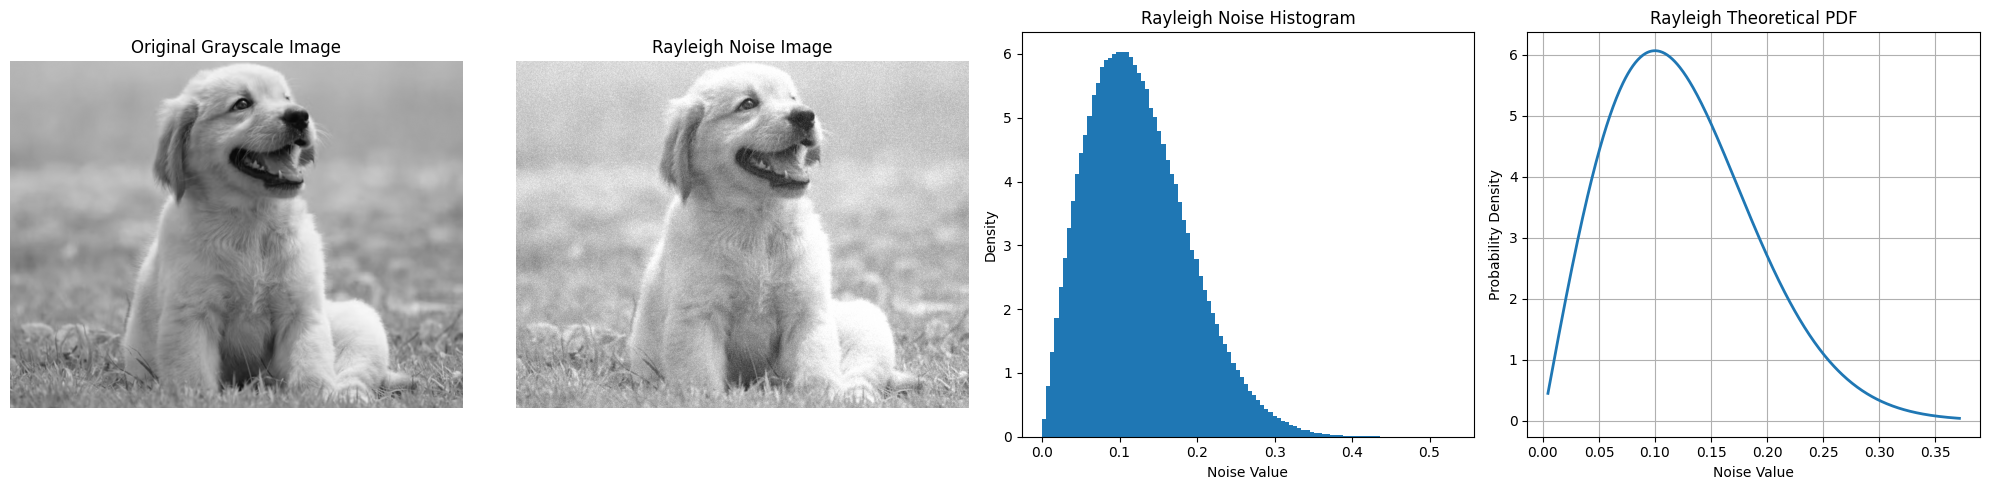

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.stats import uniform, norm, gamma, expon, rayleigh

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))

if image is None:
    raise ValueError("Unable to read image")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = gray.astype(np.float64) / 255.0

np.random.seed(42)

def uniform_noise(shape):
    return np.random.uniform(-0.2, 0.2, shape)

def gaussian_noise(shape):
    return np.random.normal(0, 0.05, shape)

def erlang_noise(shape):
    return np.random.gamma(2, 0.05, shape)

def exponential_noise(shape):
    return np.random.exponential(0.05, shape)

def rayleigh_noise(shape):
    return np.random.rayleigh(0.1, shape)

distributions = {
    "Uniform": (uniform_noise, uniform(loc=-0.2, scale=0.4)),
    "Gaussian": (gaussian_noise, norm(loc=0, scale=0.05)),
    "Erlang": (erlang_noise, gamma(a=2, scale=0.05)),
    "Exponential": (exponential_noise, expon(scale=0.05)),
    "Rayleigh": (rayleigh_noise, rayleigh(scale=0.1))
}

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

for name, (noise_func, distribution) in distributions.items():
    noise = noise_func(gray.shape)
    noisy_image = np.clip(gray + noise, 0, 1)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(gray, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Original Grayscale Image")
    axes[0].axis("off")

    axes[1].imshow(noisy_image, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(name + " Noise Image")
    axes[1].axis("off")

    axes[2].hist(noise.ravel(), bins=100, density=True)
    axes[2].set_title(name + " Noise Histogram")
    axes[2].set_xlabel("Noise Value")
    axes[2].set_ylabel("Density")

    x = np.linspace(distribution.ppf(0.001), distribution.ppf(0.999), 500)
    axes[3].plot(x, distribution.pdf(x), linewidth=2)
    axes[3].set_title(name + " Theoretical PDF")
    axes[3].set_xlabel("Noise Value")
    axes[3].set_ylabel("Probability Density")
    axes[3].grid(True)

    plt.tight_layout()
    plt.show()

now by creating my own functions

Saving image.jp2 to image (2).jp2


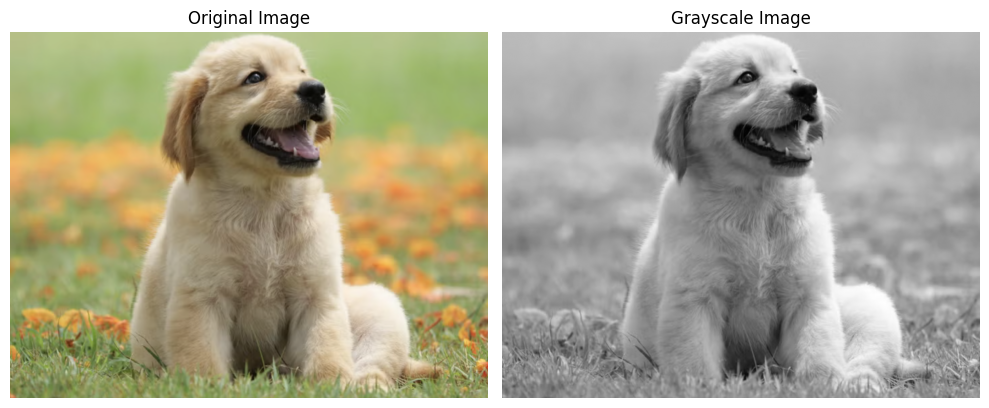

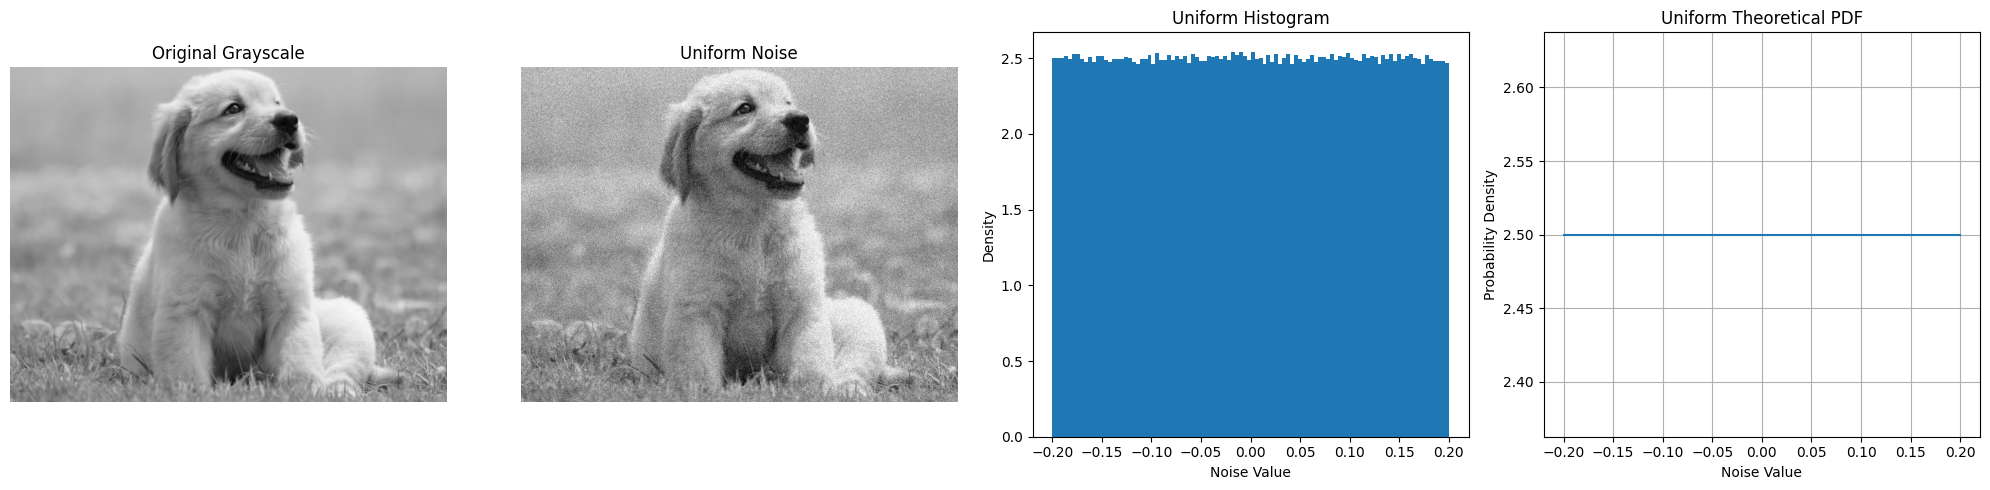

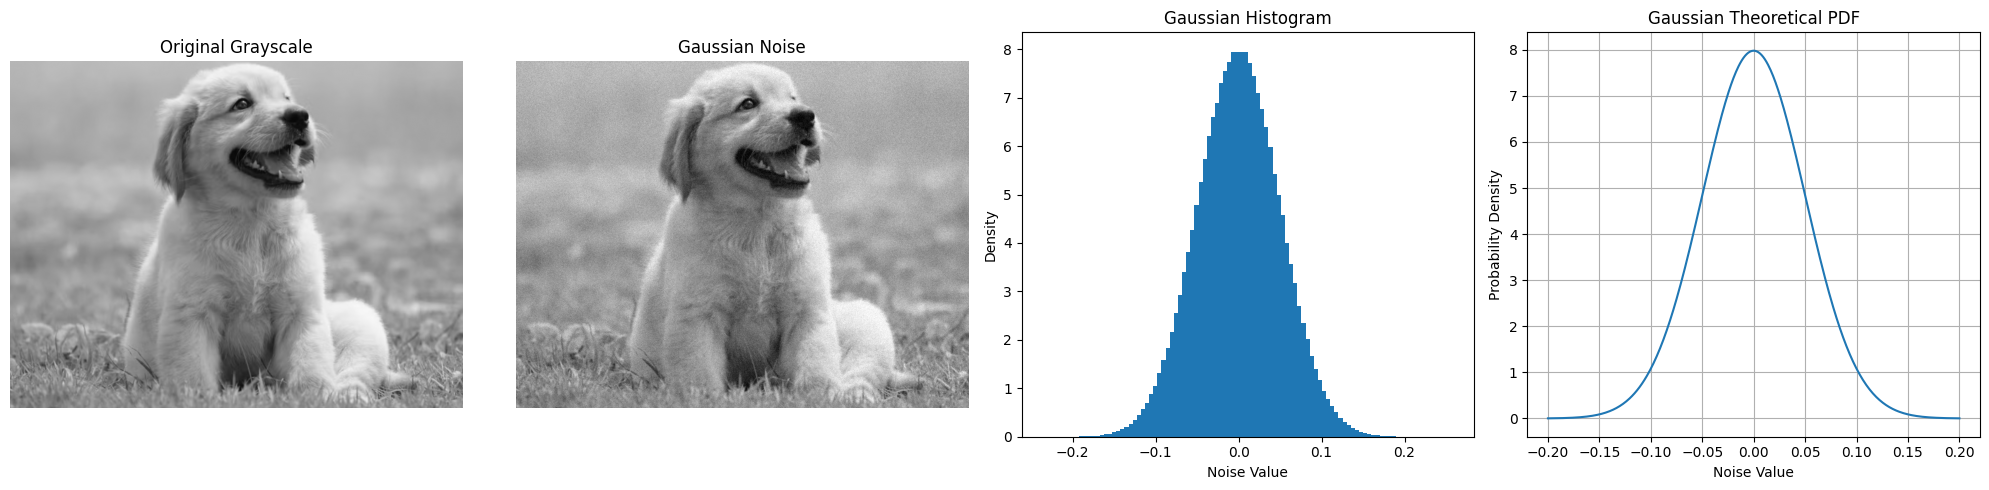

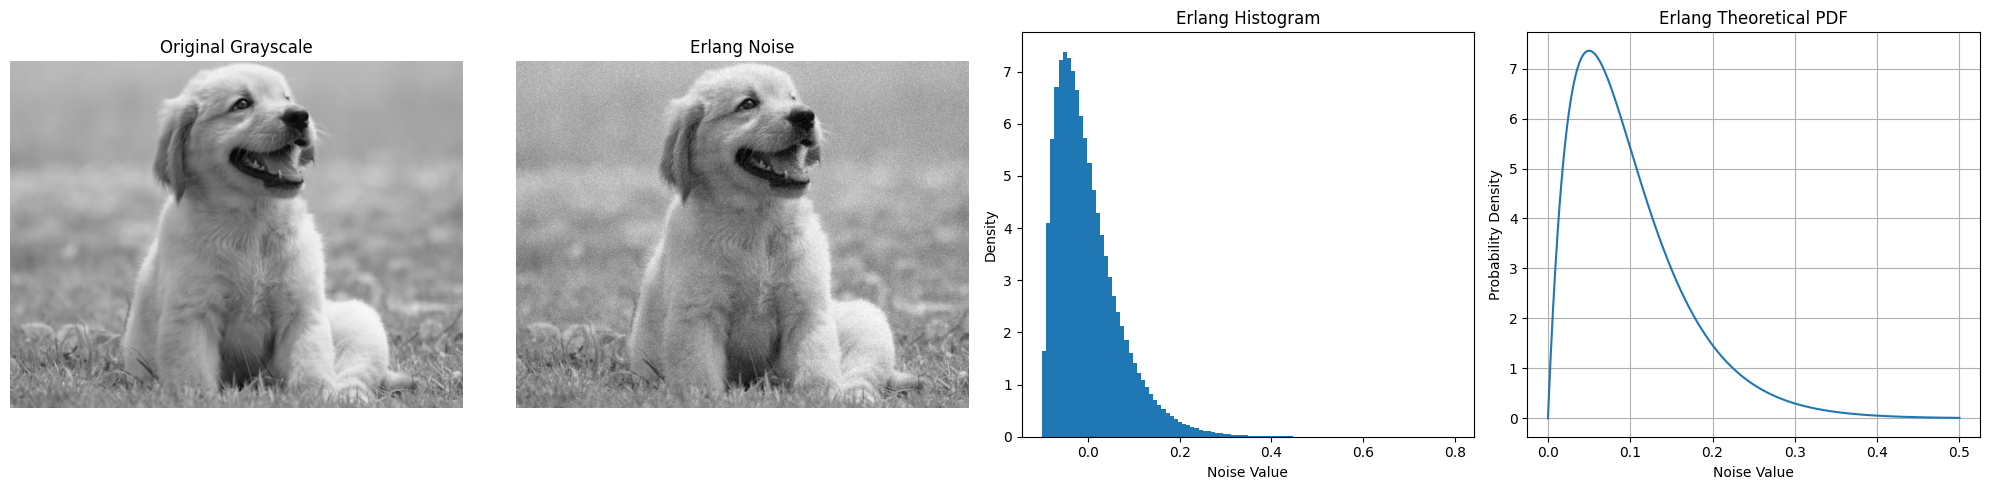

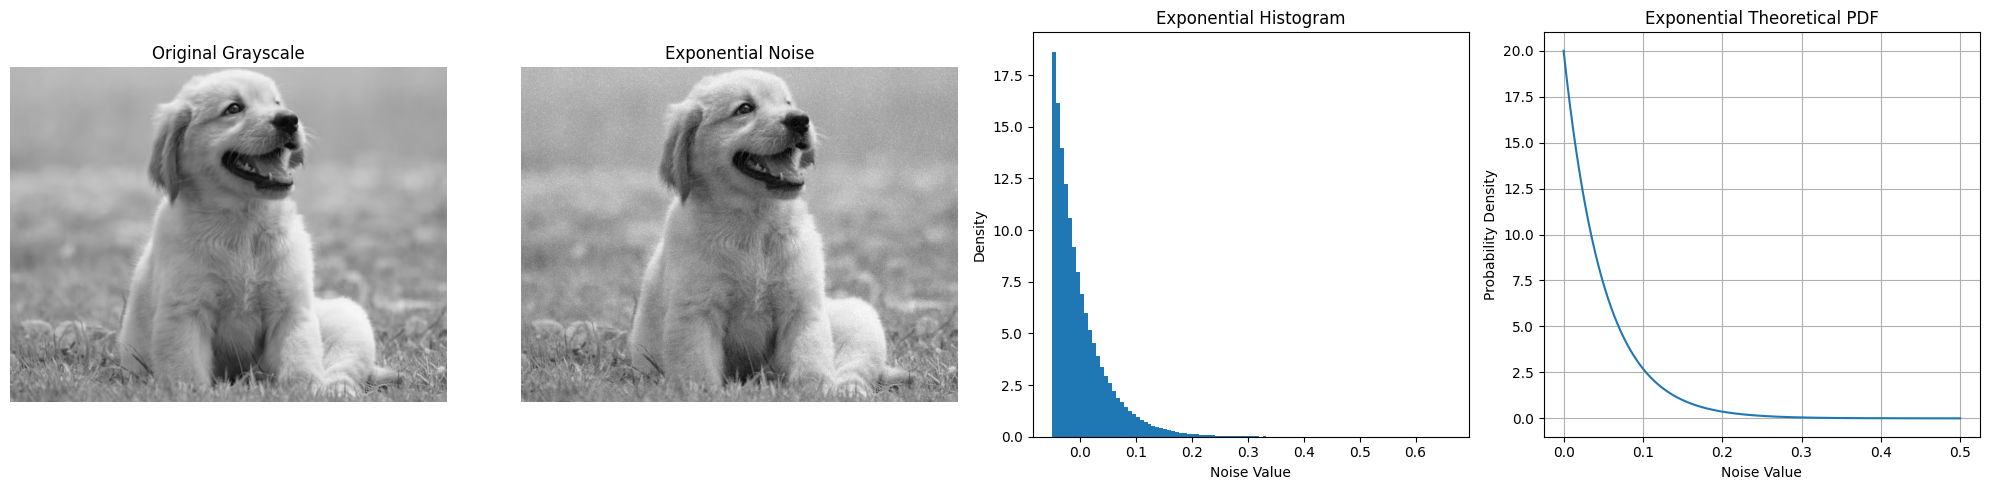

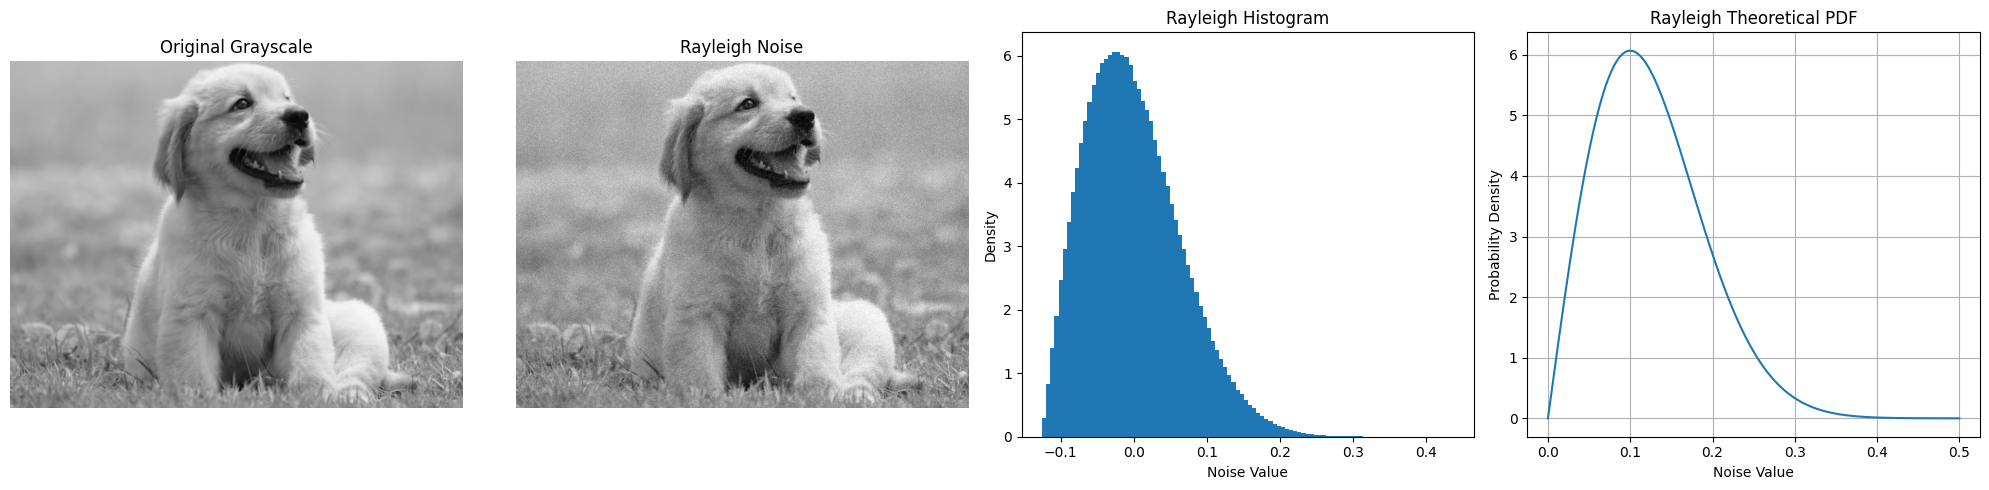

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.special import gamma

uploaded = files.upload()
image = cv2.imread(next(iter(uploaded)))

if image is None:
    raise ValueError("Unable to read image")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(float) / 255.0

def uniform_noise(shape, a=-0.2, b=0.2):
    u = np.random.rand(*shape)
    return a + (b - a) * u

def gaussian_noise(shape, mu=0, sigma=0.05):
    u1 = np.random.rand(*shape)
    u2 = np.random.rand(*shape)
    z = np.sqrt(-2 * np.log(u1 + 1e-10)) * np.cos(2 * np.pi * u2)
    return mu + sigma * z

def erlang_noise(shape, k=2, scale=0.05):
    result = np.zeros(shape)
    for i in range(k):
        result += -scale * np.log(np.random.rand(*shape) + 1e-10)
    return result

def exponential_noise(shape, scale=0.05):
    u = np.random.rand(*shape)
    return -scale * np.log(u + 1e-10)

def rayleigh_noise(shape, sigma=0.1):
    u = np.random.rand(*shape)
    return sigma * np.sqrt(-2 * np.log(1 - u + 1e-10))

def uniform_pdf(x, a=-0.2, b=0.2):
    return np.where((x >= a) & (x <= b), 1 / (b - a), 0)

def gaussian_pdf(x, mu=0, sigma=0.05):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

def erlang_pdf(x, k=2, scale=0.05):
    return np.where(x >= 0, (x ** (k - 1) * np.exp(-x / scale)) / (gamma(k) * scale ** k), 0)

def exponential_pdf(x, scale=0.05):
    return np.where(x >= 0, np.exp(-x / scale) / scale, 0)

def rayleigh_pdf(x, sigma=0.1):
    return np.where(x >= 0, (x / sigma ** 2) * np.exp(-(x ** 2) / (2 * sigma ** 2)), 0)

noise_functions = {
    "Uniform": (uniform_noise, uniform_pdf, (-0.2, 0.2)),
    "Gaussian": (gaussian_noise, gaussian_pdf, (-0.2, 0.2)),
    "Erlang": (erlang_noise, erlang_pdf, (0, 0.5)),
    "Exponential": (exponential_noise, exponential_pdf, (0, 0.5)),
    "Rayleigh": (rayleigh_noise, rayleigh_pdf, (0, 0.5))
}

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.tight_layout()
plt.show()

for name, (noise_func, pdf_func, limits) in noise_functions.items():
    noise = noise_func(gray.shape)
    if name in ("Erlang", "Exponential", "Rayleigh"):
        noise = noise - np.mean(noise)
    noisy_image = np.clip(gray + noise, 0, 1)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(gray, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Original Grayscale")
    axes[0].axis("off")

    axes[1].imshow(noisy_image, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(name + " Noise")
    axes[1].axis("off")

    axes[2].hist(noise.ravel(), bins=100, density=True)
    axes[2].set_title(name + " Histogram")
    axes[2].set_xlabel("Noise Value")
    axes[2].set_ylabel("Density")

    x = np.linspace(limits[0], limits[1], 500)
    axes[3].plot(x, pdf_func(x))
    axes[3].set_title(name + " Theoretical PDF")
    axes[3].set_xlabel("Noise Value")
    axes[3].set_ylabel("Probability Density")
    axes[3].grid(True)

    plt.tight_layout()
    plt.show()